In [3]:
import shap
import lime

print("SHAP version:", shap.__version__)
print("LIME installed successfully!")

SHAP version: 0.54.1
LIME installed successfully!


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import lime
import joblib

from pathlib import Path
from lime.lime_tabular import LimeTabularExplainer

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:

# Load synthetic dataset
df = pd.read_csv(
    "../data/raw/synthetic_atm_data.csv",
    parse_dates=["date"]
)

df = df.sort_values(
    ["date", "zone_id"]
).reset_index(drop=True)

# Feature engineering (same as Phase 4)
df["withdrawals_per_atm"] = (
    df["withdrawal_count"] /
    df["atm_count"].replace(0, np.nan)
)

df["unusual_activity_ratio"] = (
    df["unusual_activity_count"] /
    df["withdrawal_count"].replace(0, np.nan)
)

df["avg_daily_incidents_30d"] = (
    df["incidents_sum_30d"] / 30
)

df["withdrawal_amount_per_atm"] = (
    df["total_withdrawal_amount"] /
    df["atm_count"].replace(0, np.nan)
)

day_index = (
    df["date"] - pd.Timestamp("2025-01-01")
).dt.days

df["season_30d_sin"] = np.sin(
    2 * np.pi * day_index / 30
)

df["season_30d_cos"] = np.cos(
    2 * np.pi * day_index / 30
)

df = df.replace([np.inf, -np.inf], np.nan)

# Load saved model bundle
model_bundle = joblib.load(
    "../models/best_risk_classifier.joblib"
)

best_model = model_bundle["model"]
FEATURES = model_bundle["features"]
TARGET = model_bundle["target"]
CLASS_ORDER = model_bundle["class_order"]

print("Model loaded successfully!")
print("Model type:", type(best_model.named_steps["classifier"]))
print("Number of features:", len(FEATURES))
print("Target:", TARGET)

Model loaded successfully!
Model type: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Number of features: 23
Target: target_risk


In [6]:
# Recreate chronological split
unique_dates = np.sort(df["date"].unique())

split_index = int(len(unique_dates) * 0.80)

test_start = pd.Timestamp(unique_dates[split_index])
train_end = test_start - pd.Timedelta(days=7)

train_mask = df["date"] < train_end
test_mask = df["date"] >= test_start

X_train = df.loc[train_mask, FEATURES].copy()
X_test = df.loc[test_mask, FEATURES].copy()

y_train = df.loc[train_mask, TARGET].astype(str)
y_test = df.loc[test_mask, TARGET].astype(str)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Training period:",
      df.loc[train_mask, "date"].min(),
      "to",
      df.loc[train_mask, "date"].max())

print("Testing period:",
      df.loc[test_mask, "date"].min(),
      "to",
      df.loc[test_mask, "date"].max())

Training shape: (4740, 23)
Testing shape: (1212, 23)
Training period: 2025-01-31 00:00:00 to 2026-03-01 00:00:00
Testing period: 2026-03-09 00:00:00 to 2026-06-17 00:00:00


In [7]:
# Extract preprocessing and classifier
preprocessor = best_model.named_steps["preprocessor"]
classifier = best_model.named_steps["classifier"]

# Transform training and testing data
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert sparse matrices to dense if necessary
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Create DataFrames
X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names
)

print("SHAP preparation completed!")
print("Processed training:", X_train_processed.shape)
print("Processed testing:", X_test_processed.shape)

SHAP preparation completed!
Processed training: (4740, 34)
Processed testing: (1212, 34)


In [8]:

# Part 7: SHAP Global Explainability

# Select background data from training set
background = X_train_processed.sample(
    n=min(100, len(X_train_processed)),
    random_state=42
)

# Select test samples for explanation
X_explain = X_test_processed.sample(
    n=min(200, len(X_test_processed)),
    random_state=42
)

# Create SHAP Linear Explainer
explainer = shap.LinearExplainer(
    classifier,
    background
)

# Generate SHAP explanations
shap_values = explainer(X_explain)

print("SHAP explanations generated successfully!")
print("SHAP values shape:", shap_values.values.shape)
print("Classifier classes:", classifier.classes_)


SHAP explanations generated successfully!
SHAP values shape: (200, 34, 3)
Classifier classes: ['High' 'Low' 'Medium']


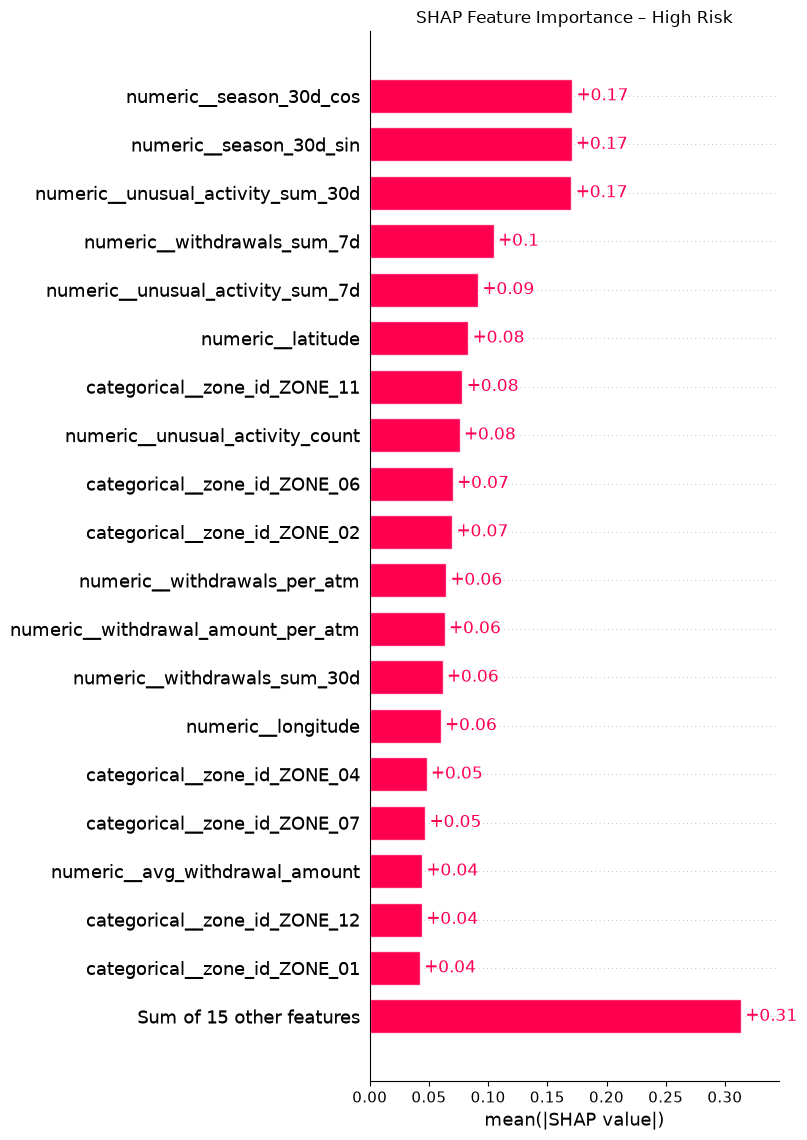

In [9]:

# Part 8: SHAP Summary Plot

# Select High-risk class
high_class_index = list(classifier.classes_).index("High")

# Extract SHAP values for High-risk predictions
high_shap = shap_values[:, :, high_class_index]

# Global feature importance
shap.plots.bar(
    high_shap,
    max_display=20,
    show=False
)

plt.title("SHAP Feature Importance – High Risk")
plt.tight_layout()
plt.savefig(
    "../results/shap_high_risk_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [10]:

# Part 9: LIME Local Explainability

# Create LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=np.asarray(X_train_processed),
    feature_names=feature_names,
    class_names=classifier.classes_.tolist(),
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Find a test sample predicted as High risk
test_predictions = classifier.predict(X_test_processed)

high_indices = np.where(test_predictions == "High")[0]

if len(high_indices) == 0:
    raise ValueError("No High-risk predictions found in test data.")

sample_index = high_indices[0]

sample = np.asarray(
    X_test_processed.iloc[sample_index]
)

# Generate local explanation

def lime_predict_fn(data):
    data = np.asarray(data)
    return classifier.predict_proba(data)

lime_exp = lime_explainer.explain_instance(
    data_row=np.asarray(X_test_processed.iloc[sample_index]),
    predict_fn=lime_predict_fn,
    num_features=15,
    labels=[high_class_index]
)

print("LIME explanation generated successfully!")
print("Actual class:", y_test.iloc[sample_index])
print("Predicted class:", test_predictions[sample_index])

# Prediction probabilities
probabilities = classifier.predict_proba(
    np.asarray(X_test_processed.iloc[[sample_index]])
)[0]

print("\nPrediction probabilities:")
for class_name, probability in zip(classifier.classes_, probabilities):
    print(f"{class_name}: {probability:.4f}")

print("\nLIME Feature Contributions:")
print(lime_exp.as_list(label=high_class_index))

LIME explanation generated successfully!
Actual class: Medium
Predicted class: High

Prediction probabilities:
High: 0.3871
Low: 0.2509
Medium: 0.3621

LIME Feature Contributions:
[('categorical__zone_id_ZONE_06 <= 0.00', -0.1820774813802702), ('categorical__zone_id_ZONE_02 <= 0.00', 0.11470933561135954), ('categorical__zone_id_ZONE_11 <= 0.00', 0.11185642947300817), ('categorical__zone_id_ZONE_12 <= 0.00', 0.11016892899308905), ('categorical__zone_id_ZONE_08 <= 0.00', -0.09891677734949346), ('categorical__zone_id_ZONE_07 <= 0.00', -0.09475396523645101), ('categorical__zone_id_ZONE_01 <= 0.00', 0.09334538346187393), ('categorical__zone_id_ZONE_04 > 0.00', 0.09230421648706993), ('numeric__season_30d_cos <= -0.96', -0.0867228094980401), ('categorical__zone_id_ZONE_09 <= 0.00', -0.07993894937731405), ('categorical__zone_id_ZONE_03 <= 0.00', 0.06949917744561704), ('numeric__withdrawals_sum_7d <= -0.86', 0.06789468745718782), ('numeric__unusual_activity_count <= -0.76', 0.054937816973551754

c:\Users\Vipin Soni\OneDrive\Desktop\Cybercrime-Cash-Withdrawal-Forecast\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


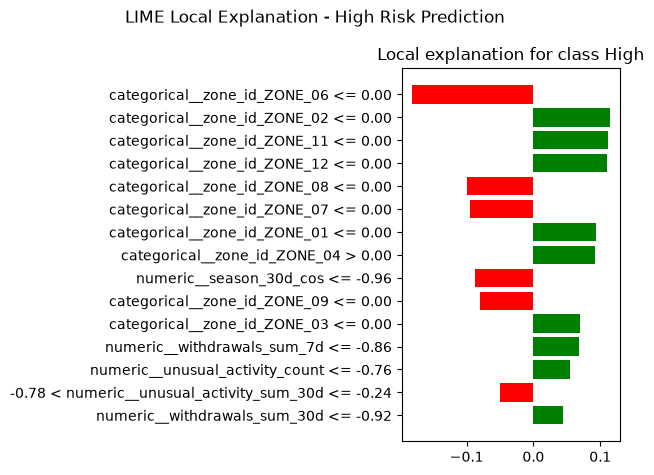

In [11]:
# Part 10: LIME Local Explanation Visualization

fig = lime_exp.as_pyplot_figure(label=high_class_index)

fig.suptitle("LIME Local Explanation - High Risk Prediction")

fig.tight_layout()

fig.savefig(
    "../results/lime_high_risk_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
import joblib
import pandas as pd

# Load model and dataset
bundle = joblib.load("../models/best_risk_classifier.joblib")
df = pd.read_csv("../data/raw/synthetic_atm_data.csv")

features = bundle["features"]

print("MODEL FEATURES:")
print(features)

print("\nMISSING FEATURES:")
print([f for f in features if f not in df.columns])

MODEL FEATURES:
['zone_id', 'latitude', 'longitude', 'day_of_week', 'month', 'is_weekend', 'atm_count', 'withdrawal_count', 'avg_withdrawal_amount', 'total_withdrawal_amount', 'unusual_activity_count', 'withdrawals_sum_7d', 'unusual_activity_sum_7d', 'incidents_sum_7d', 'withdrawals_sum_30d', 'unusual_activity_sum_30d', 'incidents_sum_30d', 'withdrawals_per_atm', 'unusual_activity_ratio', 'avg_daily_incidents_30d', 'withdrawal_amount_per_atm', 'season_30d_sin', 'season_30d_cos']

MISSING FEATURES:
['withdrawals_per_atm', 'unusual_activity_ratio', 'avg_daily_incidents_30d', 'withdrawal_amount_per_atm', 'season_30d_sin', 'season_30d_cos']


In [13]:

import pandas as pd
import numpy as np
from pathlib import Path

# Load original dataset
df = pd.read_csv(
    "../data/raw/synthetic_atm_data.csv",
    parse_dates=["date"]
)

df = df.sort_values(
    ["date", "zone_id"]
).reset_index(drop=True)

# Create the six missing features
df["withdrawals_per_atm"] = (
    df["withdrawal_count"] /
    df["atm_count"].replace(0, np.nan)
)

df["unusual_activity_ratio"] = (
    df["unusual_activity_count"] /
    df["withdrawal_count"].replace(0, np.nan)
)

df["avg_daily_incidents_30d"] = (
    df["incidents_sum_30d"] / 30
)

df["withdrawal_amount_per_atm"] = (
    df["total_withdrawal_amount"] /
    df["atm_count"].replace(0, np.nan)
)

day_index = (
    df["date"] - pd.Timestamp("2025-01-01")
).dt.days

df["season_30d_sin"] = np.sin(
    2 * np.pi * day_index / 30
)

df["season_30d_cos"] = np.cos(
    2 * np.pi * day_index / 30
)

df = df.replace([np.inf, -np.inf], np.nan)

# Save the processed CSV
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "batch_prediction_sample.csv"
df.to_csv(output_file, index=False)

print("CSV created:", output_file)
print("Dataset shape:", df.shape)


CSV created: ..\data\processed\batch_prediction_sample.csv
Dataset shape: (6036, 27)
